# Arizona Cardinals Defense: Efficiency Over the Years

**What this notebook shows**
1. **Section A:** how efficient the Cardinals defense has been in every season nflverse has recorded (1999 to the current season)
2. **Section B:** blitz rate vs. defensive efficiency
3. **Section C:** man coverage rate vs. defensive efficiency
4. **Section D:** pressure rate vs. defensive efficiency

**How to use it:** read the explanation above each gray code box, then run the box with **Shift + Enter**. You can also click **Run All**.

**How long it takes:** each run downloads about 28 seasons of play-by-play data, which takes about 3–5 minutes.

## Step 1 — Setup

We load the tools:
- `nflreadpy` downloads the NFL data
- `pandas` works with tables
- `matplotlib` draws the charts

We also set the seasons to use:
- **Efficiency:** 1999 is the first season nflverse has play-by-play data for. The last season is the current one, which nflreadpy looks up for us.
- **Blitz, pressure, and coverage:** these come from play-level charting, which nflreadpy offers for **2016–2025** only. Man/zone coverage starts in **2018**.

In [1]:
import nflreadpy as nfl
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

TEAM = "ARI"
FIRST_SEASON = 1999
CURRENT_SEASON = nfl.get_current_season()
EFFICIENCY_SEASONS = list(range(FIRST_SEASON, CURRENT_SEASON + 1))
CHARTING_SEASONS = list(range(2016, 2026))

Path("figures").mkdir(exist_ok=True)
print(f"Efficiency seasons: {FIRST_SEASON}-{CURRENT_SEASON}")
print(f"Blitz / pressure / coverage seasons: {CHARTING_SEASONS[0]}-{CHARTING_SEASONS[-1]}")

Efficiency seasons: 1999-2026
Blitz / pressure / coverage seasons: 2016-2025


## Step 2 — Download the data

**Play-by-play:** one row per play, with EPA (Expected Points Added). For a defense, **lower EPA allowed is better**.

We download one season at a time and keep only the 9 columns we need, out of about 370. Loading all 28 seasons with every column would use several gigabytes of memory.

We keep only regular-season run and pass plays, the same rule used in the other notebooks. We do this for **every team**, not just Arizona, so we can compare the Cardinals to the rest of the league.

**Participation (2016–2025):** one row per play, with:
- `was_pressure`: was the QB pressured?
- `number_of_pass_rushers`
- `defense_man_zone_type`: man or zone coverage

In some older seasons the play ID is stored as a decimal number, so we convert it to a whole number in both tables. That way the plays match up.

In [2]:
PBP_COLUMNS = ["game_id", "play_id", "season", "week", "season_type", "defteam",
               "play_type", "qb_dropback", "epa"]

pbp_parts = []
for season in EFFICIENCY_SEASONS:
    season_plays = (nfl.load_pbp(seasons=[season])
                    .select(PBP_COLUMNS)
                    .filter((pl.col("season_type") == "REG")
                            & pl.col("play_type").is_in(["pass", "run"])
                            & pl.col("epa").is_not_null())
                    .with_columns(pl.col("play_id").cast(pl.Int64)))
    pbp_parts.append(season_plays.to_pandas())
plays = pd.concat(pbp_parts, ignore_index=True)

participation = pd.concat([
    nfl.load_participation(seasons=[season])
       .select(["nflverse_game_id", "play_id", "was_pressure",
                "number_of_pass_rushers", "defense_man_zone_type"])
       .with_columns(pl.col("play_id").cast(pl.Int64))
       .to_pandas()
    for season in CHARTING_SEASONS
], ignore_index=True)

print(f"Seasons loaded: {plays['season'].min()}-{plays['season'].max()}")
print(f"Plays: {len(plays):,}   Participation rows: {len(participation):,}")

Seasons loaded: 1999-2026
Plays: 881,702   Participation rows: 478,989


## Step 3 — Build one row per defense per season

**Efficiency (all seasons)**
- `epa_per_play_allowed`: average EPA on every run and pass play against the defense
- `rank`: where the team ranked that season (1 = best). There were 31 teams from 1999 to 2001 and 32 from 2002 on.

**Charting rates (pass plays only, 2016–2025).** Each rate uses only the plays that were charted.

| Rate | Meaning |
|---|---|
| `pressure_rate` | Share of dropbacks where the QB was pressured |
| `blitz_rate` | Share of dropbacks with **5 or more** pass rushers (the standard definition of a blitz). Impossible counts, like 0 or more than 11 rushers, are treated as unknown. |
| `man_rate` | Share of charted dropbacks in man coverage (2018 on) |

**Why "vs. league average"?** The way plays were charted changed over the years. For example, the league-wide pressure rate jumps from about 25% (2016–17) to about 30% (2018 on), and the man coverage rate swings from 29% to 48% and back to 31% between 2022 and 2025. Those swings mostly reflect changes in charting, not in how teams played.

To compare years fairly, we also measure each number **against that season's league average**:
- **+5 points of blitz rate** means the defense blitzed 5 percentage points more than a typical team that year.
- **EPA vs. average of −0.05** means it allowed 0.05 fewer points per play than a typical defense that year.

In [3]:
team_seasons = (plays.groupby(["season", "defteam"])
                .agg(plays=("epa", "size"), epa_per_play_allowed=("epa", "mean"))
                .reset_index().rename(columns={"defteam": "team"}))
team_seasons["rank"] = team_seasons.groupby("season")["epa_per_play_allowed"].rank(method="min").astype(int)
team_seasons["teams_that_season"] = team_seasons.groupby("season")["team"].transform("size")

dropbacks = plays[(plays["qb_dropback"] == 1) & plays["season"].isin(CHARTING_SEASONS)].merge(
    participation, left_on=["game_id", "play_id"], right_on=["nflverse_game_id", "play_id"], how="left")

rushers = dropbacks["number_of_pass_rushers"].where(dropbacks["number_of_pass_rushers"].between(1, 11))
dropbacks["pressure"] = dropbacks["was_pressure"].astype(float)
dropbacks["blitz"] = (rushers >= 5).astype(float).where(rushers.notna())
dropbacks["man"] = dropbacks["defense_man_zone_type"].map({"MAN_COVERAGE": 1.0, "ZONE_COVERAGE": 0.0})

rates = (dropbacks.groupby(["season", "defteam"])[["pressure", "blitz", "man"]].mean()
         .add_suffix("_rate").reset_index().rename(columns={"defteam": "team"}))
team_seasons = team_seasons.merge(rates, on=["season", "team"], how="left")

# Each number compared with that season's league average
for col in ["epa_per_play_allowed", "pressure_rate", "blitz_rate", "man_rate"]:
    team_seasons[col + "_vs_avg"] = team_seasons[col] - team_seasons.groupby("season")[col].transform("mean")

arizona = team_seasons[team_seasons["team"] == TEAM].set_index("season")
print(f"{len(team_seasons):,} team-seasons in total; {len(arizona)} for Arizona")
arizona[["plays", "epa_per_play_allowed", "rank", "pressure_rate", "blitz_rate", "man_rate"]].round(3).tail(12)

893 team-seasons in total; 28 for Arizona


,plays,epa_per_play_allowed,rank,pressure_rate,blitz_rate,man_rate
season,,,,,,
2015,978,-0.104,5,NaN,NaN,NaN
2016,1009,-0.095,4,0.269,0.427,NaN
2017,1005,-0.100,6,0.281,0.314,NaN
2018,1058,0.030,20,0.295,0.418,0.232
2019,1067,0.096,28,0.327,0.391,0.375
2020,1047,0.007,11,0.312,0.383,0.444
2021,1025,-0.049,6,0.279,0.351,0.278
2022,1060,0.016,23,0.298,0.359,0.199
2023,1047,0.085,32,0.256,0.144,0.326


## Step 4 — Check that the numbers look right

1. **Every Arizona season is present**, 1999 through the current season, with no gaps.
2. **Arizona's play counts are realistic.** A full season is about 950–1,150 run/pass plays. The current season will be lower because it's still in progress.
3. **Team counts:** 31 teams per season through 2001, then 32 once the Texans joined in 2002.
4. **League average EPA per play is near 0 each season.**
5. **Charting coverage:** at least 85% of Arizona's dropbacks have a pressure flag in every charted season.
6. **Known seasons:** the 2008 team that reached the Super Bowl should be close to league average, while the 2015 team that went 13–3 should be one of the better defenses. These are spot checks, not strict rules.

In [4]:
def check(label, ok, detail):
    print(f"[{'PASS' if ok else 'CHECK'}] {label}: {detail}")

missing = sorted(set(EFFICIENCY_SEASONS) - set(arizona.index))
check("1. every Arizona season present", not missing, f"missing: {missing or 'none'}")

full = arizona.drop(index=CURRENT_SEASON, errors="ignore")
check("2. full-season play counts 900-1200", full["plays"].between(900, 1200).all(),
      f"range {full['plays'].min()}-{full['plays'].max()}")
weeks_so_far = plays.loc[plays["season"] == CURRENT_SEASON, "week"].max()
print(f"         {CURRENT_SEASON} so far: {arizona.loc[CURRENT_SEASON, 'plays']} plays through week {weeks_so_far}")

counts = team_seasons.groupby("season").size()
check("3. 31 teams through 2001, 32 after",
      (counts[counts.index <= 2001] == 31).all() and (counts[counts.index >= 2002] == 32).all(),
      f"{counts.min()}-{counts.max()} teams per season")

league_epa = plays.groupby("season")["epa"].mean()
check("4. league EPA near 0 every season", league_epa.abs().max() < 0.06,
      f"range {league_epa.min():+.3f} to {league_epa.max():+.3f}")

ari_db = dropbacks[dropbacks["defteam"] == TEAM]
charted = ari_db.groupby("season")["pressure"].apply(lambda s: s.notna().mean())
check("5. Arizona dropbacks with a pressure flag >= 85%", (charted >= 0.85).all(),
      f"lowest {charted.min():.0%} ({charted.idxmin()})")

for season in [2008, 2015]:
    row = arizona.loc[season]
    print(f"   6. {season}: ranked {row['rank']} of {row['teams_that_season']} "
          f"(EPA per play allowed {row['epa_per_play_allowed']:+.3f})")

[PASS] 1. every Arizona season present: missing: none
[PASS] 2. full-season play counts 900-1200: range 927-1078
         2026 so far: 352 plays through week 6
[PASS] 3. 31 teams through 2001, 32 after: 31-32 teams per season
[PASS] 4. league EPA near 0 every season: range -0.056 to +0.031
[PASS] 5. Arizona dropbacks with a pressure flag >= 85%: lowest 87% (2018)
   6. 2008: ranked 23 of 32 (EPA per play allowed +0.031)
   6. 2015: ranked 5 of 32 (EPA per play allowed -0.104)


## Section A — Arizona's defensive efficiency, every season

The **blue line** is Arizona's EPA per play allowed. The **dashed gray line** is the league average.

**Higher on the chart is better.** Lower EPA allowed means a better defense, so the axis is flipped. Seasons above the gray line were better than average, and seasons below it were worse.

The current season is drawn as a **hollow dot** because it's only partly played. The best and worst seasons are labeled, along with their league rank.

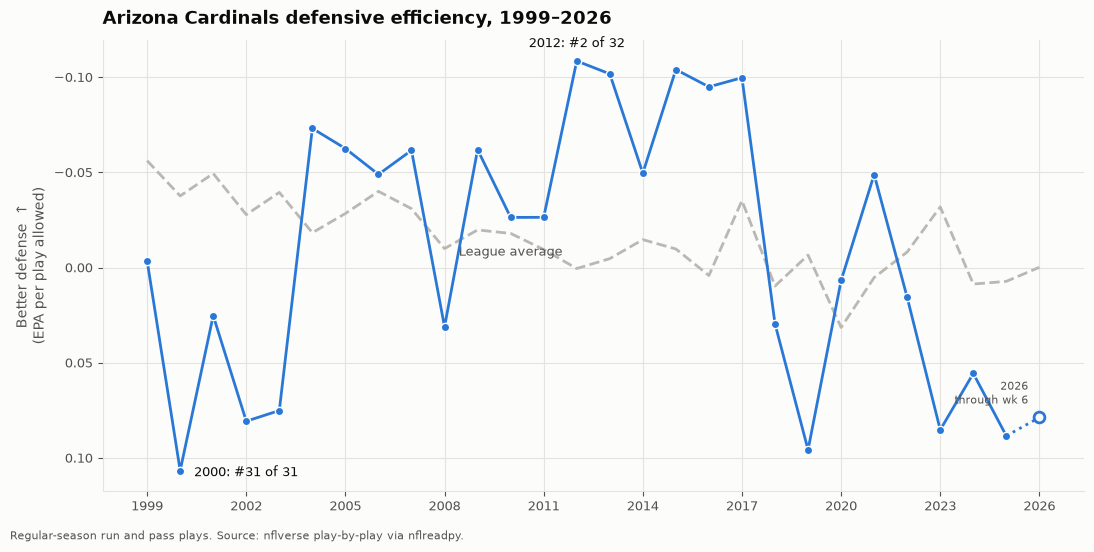

In [5]:
BLUE, INK, INK_2, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#b9b8b2", "#e4e3df", "#fcfcfb"

def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8, zorder=0)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=9)

complete = arizona.drop(index=CURRENT_SEASON, errors="ignore")
fig, ax = plt.subplots(figsize=(11, 5.5), facecolor=SURFACE)
style(ax)
ax.plot(league_epa.index, league_epa.values, color=MUTED, linewidth=2, linestyle="--", zorder=2)
ax.annotate("League average", (2010, league_epa.loc[2010]), xytext=(0, -16),
            textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.plot(complete.index, complete["epa_per_play_allowed"], color=BLUE, linewidth=2, marker="o",
        markersize=6, markeredgecolor=SURFACE, zorder=3)
if CURRENT_SEASON in arizona.index:
    last_full = complete.index.max()
    now = arizona.loc[CURRENT_SEASON, "epa_per_play_allowed"]
    ax.plot([last_full, CURRENT_SEASON], [complete.loc[last_full, "epa_per_play_allowed"], now],
            color=BLUE, linewidth=2, linestyle=":", zorder=3)
    ax.scatter([CURRENT_SEASON], [now], s=60, facecolor=SURFACE, edgecolor=BLUE, linewidth=2, zorder=4)
    ax.annotate(f"{CURRENT_SEASON}\nthrough wk {weeks_so_far}", (CURRENT_SEASON, now), xytext=(-8, 10),
                textcoords="offset points", ha="right", fontsize=8, color=INK_2)

# Label the best season above its dot and the worst season to the right of its dot
best, worst = complete["epa_per_play_allowed"].idxmin(), complete["epa_per_play_allowed"].idxmax()
for season, offset, align in [(best, (0, 10), "center"), (worst, (10, -4), "left")]:
    row = complete.loc[season]
    ax.annotate(f"{season}: #{row['rank']} of {row['teams_that_season']}",
                (season, row["epa_per_play_allowed"]), xytext=offset, textcoords="offset points",
                ha=align, fontsize=9, color=INK)

ax.invert_yaxis()
ax.set_xticks(range(FIRST_SEASON, CURRENT_SEASON + 1, 3))
ax.set_ylabel("Better defense  ↑\n(EPA per play allowed)", color=INK_2)
ax.set_title(f"Arizona Cardinals defensive efficiency, {FIRST_SEASON}–{CURRENT_SEASON}",
             loc="left", fontsize=13, fontweight="bold", color=INK, pad=12)
fig.text(0.01, 0.01, "Regular-season run and pass plays. Source: nflverse play-by-play via nflreadpy.",
         fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/ari_defense_efficiency_by_season.png", dpi=200, facecolor=SURFACE)
plt.show()

The table below gives the same numbers season by season, with Arizona's league rank (1 = best defense that year).

In [6]:
table = arizona[["epa_per_play_allowed", "epa_per_play_allowed_vs_avg", "rank", "teams_that_season"]].copy()
table.columns = ["EPA per play allowed", "vs. league average", "Rank", "Teams"]
better = (table["vs. league average"] < 0).sum()
print(f"Better than league average in {better} of {len(table)} seasons")
table.round(3)

Better than league average in 15 of 28 seasons


,EPA per play allowed,vs. league average,Rank,Teams
season,,,,
1999,-0.004,0.054,24,31
2000,0.107,0.147,31,31
2001,0.025,0.075,26,31
2002,0.081,0.110,31,32
2003,0.075,0.115,31,32
2004,-0.073,-0.054,9,32
2005,-0.063,-0.034,9,32
2006,-0.049,-0.008,14,32
2007,-0.062,-0.031,12,32


## How Sections B, C, and D work

Each section compares one defensive habit with efficiency, using the same kind of chart:
- **Every dot is one NFL defense in one season.** Gray dots are the rest of the league; **blue dots are Arizona**, labeled with the year (`'21` = 2021).
- **Left to right:** how much more (or less) of the habit the defense used than the league average that year.
- **Up:** better efficiency than the league average that year.
- **The gray line is the trend across all teams.** If it rises to the right, using more of the habit went with better defense. If it's flat, there's no link.
- **r** measures how tightly the dots follow the trend. It runs from −1 to +1, and **r²** is the share of the differences between defenses that the habit explains.

Each chart prints two r values: one for **all teams** (hundreds of dots, a reliable reading) and one for **Arizona only** (just 8–10 dots, so treat it as a rough hint).

The code below defines this chart once, so each section can reuse it with one line.

In [7]:
def compare_with_efficiency(rate, name, filename):
    data = team_seasons.dropna(subset=[rate])
    x_all = data[rate + "_vs_avg"] * 100
    y_all = data["epa_per_play_allowed_vs_avg"]
    is_ari = data["team"] == TEAM

    slope, intercept = np.polyfit(x_all, y_all, 1)
    r_all = x_all.corr(y_all)
    r_ari = x_all[is_ari].corr(y_all[is_ari])
    seasons = f"{data['season'].min()}–{data['season'].max()}"

    print(f"All teams, {seasons} ({len(data)} team-seasons): r = {r_all:+.2f}  ->  explains {r_all**2:.0%}")
    print(f"Arizona only ({is_ari.sum()} seasons):            r = {r_ari:+.2f}  ->  explains {r_ari**2:.0%}")

    fig, ax = plt.subplots(figsize=(10, 6), facecolor=SURFACE)
    style(ax)
    ax.scatter(x_all[~is_ari], y_all[~is_ari], s=22, color=MUTED, alpha=0.6, linewidth=0, zorder=2)
    xs = np.linspace(x_all.min(), x_all.max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK_2, linewidth=2, zorder=3)
    ax.scatter(x_all[is_ari], y_all[is_ari], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=4)
    for season, x, y in zip(data.loc[is_ari, "season"], x_all[is_ari], y_all[is_ari]):
        ax.annotate(f"'{str(season)[2:]}", (x, y), xytext=(6, 3), textcoords="offset points",
                    fontsize=9, color=INK, fontweight="bold")

    ax.axhline(0, color=GRID, linewidth=1.2, zorder=1)
    ax.axvline(0, color=GRID, linewidth=1.2, zorder=1)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0f}"))
    ax.set_xlabel(f"{name}: percentage points vs. league average that season  →  more", color=INK_2)
    ax.set_ylabel("Better defense  ↑\n(EPA per play allowed vs. league average)", color=INK_2)
    ax.set_title(f"{name} vs. defensive efficiency, {seasons}\n"
                 f"All teams r = {r_all:+.2f}  ·  Arizona r = {r_ari:+.2f}",
                 loc="left", fontsize=12, fontweight="bold", color=INK, pad=12)
    fig.text(0.01, 0.01, "Gray: every NFL defense-season. Blue: Arizona. Gray line: trend across all teams. "
             "Source: nflverse via nflreadpy.", fontsize=8, color=INK_2)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(f"figures/{filename}", dpi=200, facecolor=SURFACE)
    plt.show()

    ari = arizona.loc[arizona[rate].notna(), [rate, rate + "_vs_avg", "epa_per_play_allowed", "rank"]].copy()
    ari[[rate, rate + "_vs_avg"]] *= 100
    ari.columns = [f"{name} %", "vs. league avg (pts)", "EPA per play allowed", "Rank"]
    return ari.round(3)

## Section B — Blitz rate vs. defensive efficiency (2016–2025)

A **blitz** sends **5 or more** pass rushers, so at least one player who usually stays back in coverage rushes the QB instead.

Blitzing is a trade-off. It can get to the QB faster, but it leaves fewer players to cover receivers. The question here is whether defenses that blitzed more than average were more efficient.

All teams, 2016–2025 (320 team-seasons): r = -0.10  ->  explains 1%
Arizona only (10 seasons):            r = -0.53  ->  explains 28%


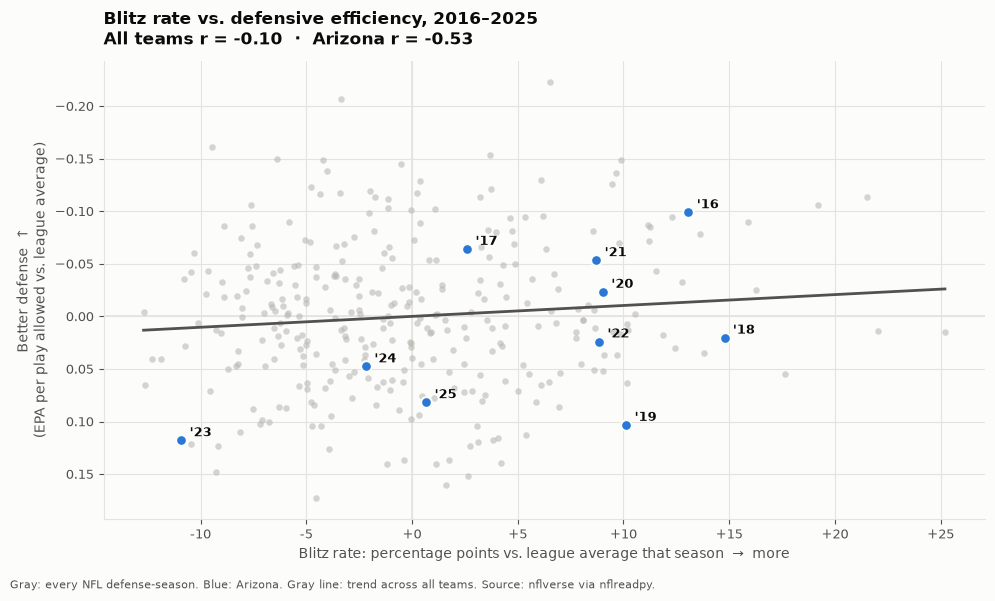

,Blitz rate %,vs. league avg (pts),EPA per play allowed,Rank
season,,,,
2016,42.736,13.072,-0.095,4
2017,31.386,2.608,-0.100,6
2018,41.783,14.777,0.030,20
2019,39.098,10.132,0.096,28
2020,38.308,9.031,0.007,11
2021,35.105,8.714,-0.049,6
2022,35.945,8.847,0.016,23
2023,14.411,-10.910,0.085,32
2024,24.522,-2.173,0.056,26


In [8]:
compare_with_efficiency("blitz_rate", "Blitz rate", "ari_blitz_vs_efficiency.png")

## Section C — Man coverage rate vs. defensive efficiency (2018–2025)

In **man coverage**, each defender follows one receiver. In **zone coverage**, defenders guard areas of the field. The data marks man vs. zone starting in 2018.

The question here is whether defenses that played more man than average were more efficient.

All teams, 2018–2025 (256 team-seasons): r = +0.01  ->  explains 0%
Arizona only (8 seasons):            r = -0.29  ->  explains 9%


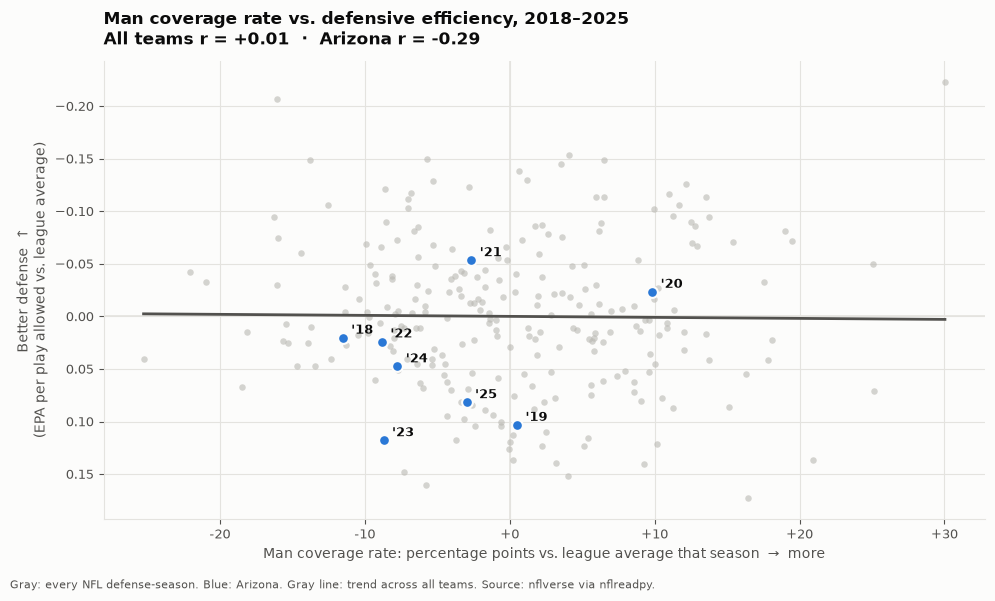

,Man coverage rate %,vs. league avg (pts),EPA per play allowed,Rank
season,,,,
2018,23.200,-11.516,0.030,20
2019,37.521,0.512,0.096,28
2020,44.366,9.839,0.007,11
2021,27.828,-2.646,-0.049,6
2022,19.932,-8.812,0.016,23
2023,32.632,-8.699,0.085,32
2024,40.777,-7.749,0.056,26
2025,27.858,-2.969,0.088,27


In [9]:
compare_with_efficiency("man_rate", "Man coverage rate", "ari_man_coverage_vs_efficiency.png")

## Section D — Pressure rate vs. defensive efficiency (2016–2025)

A **pressure** is any dropback where the QB was hurried, hit, or sacked.

Unlike blitzing or man coverage, pressure is a **result**, not a play call. A defense can get pressure with four rushers, and a blitz can fail to get any. The question here is whether defenses that pressured the QB more than average were more efficient.

All teams, 2016–2025 (320 team-seasons): r = -0.38  ->  explains 15%
Arizona only (10 seasons):            r = -0.50  ->  explains 25%


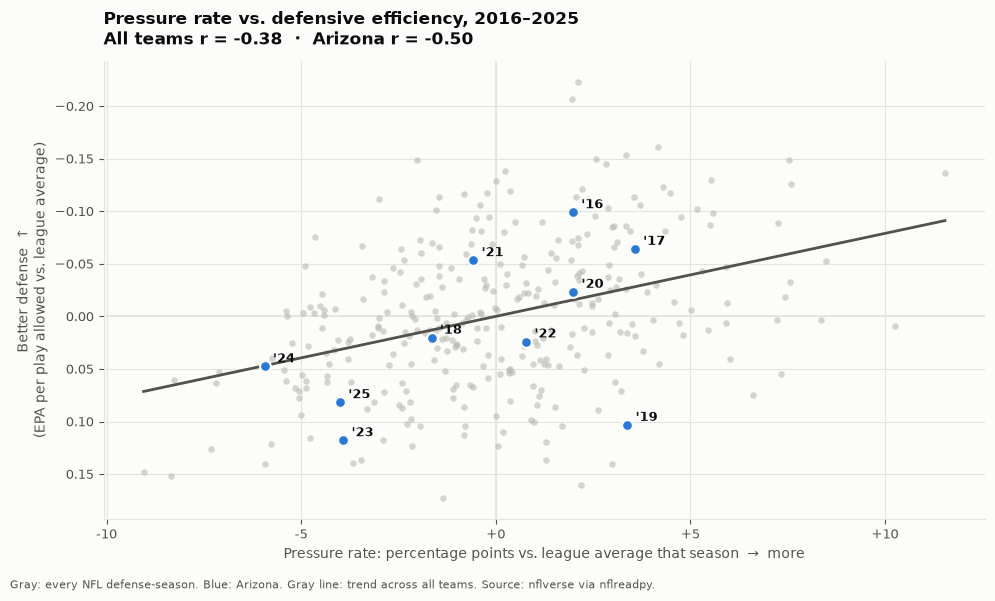

,Pressure rate %,vs. league avg (pts),EPA per play allowed,Rank
season,,,,
2016,26.874,1.983,-0.095,4
2017,28.114,3.573,-0.100,6
2018,29.482,-1.649,0.030,20
2019,32.663,3.378,0.096,28
2020,31.162,1.990,0.007,11
2021,27.907,-0.579,-0.049,6
2022,29.848,0.780,0.016,23
2023,25.569,-3.919,0.085,32
2024,24.919,-5.938,0.056,26


In [10]:
compare_with_efficiency("pressure_rate", "Pressure rate", "ari_pressure_vs_efficiency.png")

## Summary

**Section A: efficiency over the years (1999–2026)**
- Arizona's defense was better than the league average in **15 of 28 seasons**.
- The worst stretch was early: the Cardinals ranked **last in 2000 (#31 of 31)** and **second to last in 2002 and 2003 (#31 of 32)**.
- The best stretch was **2012–2017**, when the defense ranked in the top 10 every year, including **#2 in 2012** and **#3 in 2013**.
- Since **2022**, the defense has been below average every season: **#32 in 2023, #26 in 2024, #27 in 2025**, and #28 so far in 2026, though that's only through about six weeks. 2021 (#6) was the last strong year.

**Section B: blitz rate**
- **Across all teams, blitzing more had almost no link to efficiency** (r = −0.10, explaining about 1%).
- For Arizona the link looks stronger (r = −0.53). The Cardinals blitzed far more than average from 2016 to 2022 and far less from 2023 on, and the later years were worse.
- The league-wide result suggests the change in blitz rate isn't what made the difference. Arizona's low-blitz years also came with a new coaching staff and roster.

**Section C: man coverage rate**
- **Playing more man coverage had no link to efficiency, league-wide** (r = +0.01) or for Arizona (r = −0.29, from only 8 seasons, which is too few to mean much).
- Arizona played less man than average in most seasons, in both its good and bad years.

**Section D: pressure rate**
- **Pressure is the strongest of the three** (all teams r = −0.38, explaining about 15%). Defenses that pressure the QB more than average tend to be more efficient.
- Arizona follows the pattern (r = −0.50). From **2023 to 2025 its pressure rate was 4–6 points below average**, among the lowest in the league, and those were some of its worst defensive seasons.
- Pressure isn't everything, though. In **2019** Arizona pressured the QB more than average but still ranked #28.

**Bottom line:** of the three habits, **only pressure rate lines up with defensive efficiency in a meaningful way**. Blitzing and man coverage are play-calling choices that work for some teams and not others. For Arizona, the recent decline goes along with a pass rush that stopped getting home. The main notebook (`defense_pressure_vs_coverage.ipynb`) found that coverage quality on clean-pocket throws matters even more than pressure.

**Keep in mind**
- These comparisons show what tends to go together, not what causes what.
- Arizona's own r values are based on only 8–10 seasons, so the all-teams numbers are more reliable.
- Charting changed over the years. That's why every rate is measured against that season's league average.